In [1]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
import pickle
import sys
sys.path.insert(0,'../src/')



from utils import *
from multiply_connected_pipe import *
from pipe_system import PipeSystem
from abstract_pipe import *
from curve import *

# Set up plotting parameters
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


#### geometry creation

In [2]:
# Goal 1: Create T-shaped and L-shaped pipe junctions

print("Creating T-shaped pipe junctions...")

# Create T-shaped junction
# Parameters: length, radius, corner_size
t_pipe = TShaped(l=5.0, r=0.5, corner_size=1)
print(f"T-shaped pipe created with {t_pipe.n_lets} outlets")


# Build geometry for both pipes
print("\nBuilding pipe geometries...")
t_pipe.build_geometry(required_tol=1e-6)

print(f"T-pipe: {t_pipe.n_pts} boundary points")

Creating T-shaped pipe junctions...
1
1
T-shaped pipe created with 3 outlets

Building pipe geometries...
T-pipe: 2640 boundary points


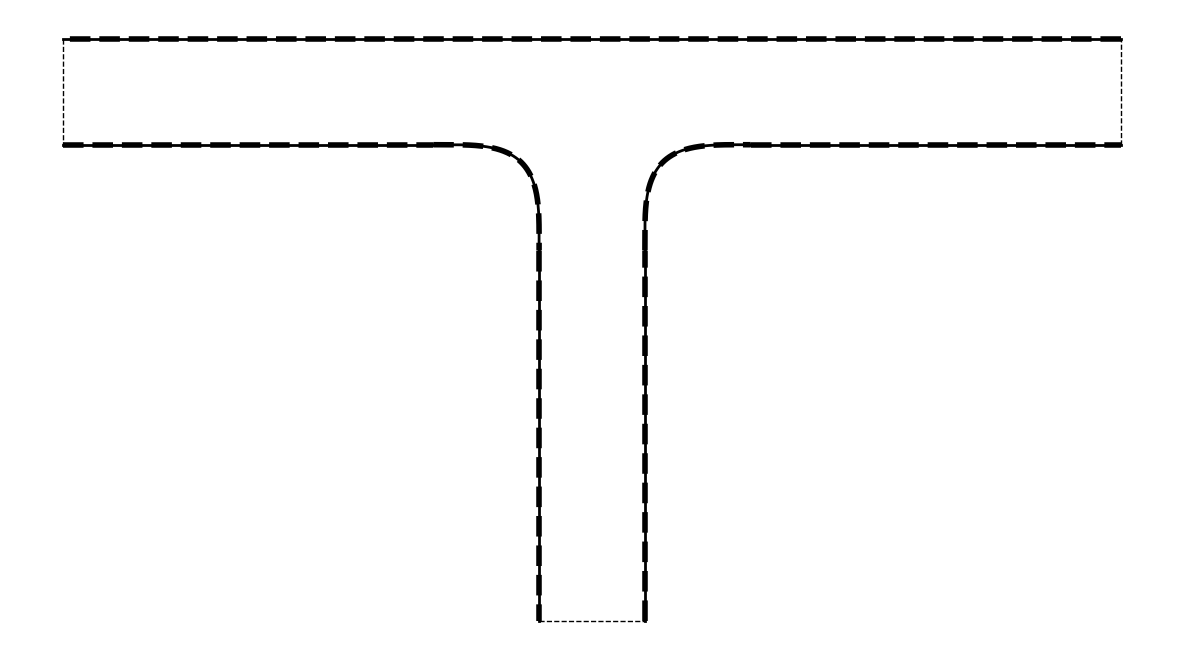

In [3]:
# Visualize the pipe geometries using the boundary plotting method
fig, ax = plt.subplots(tight_layout=True)

# Plot T-shaped pipe
ax.set_aspect('equal')
ax.axis('off')
t_pipe.exterior_boundary.plot_plyg_bdr(ax,color='k')

plt.show()

In [4]:
# Goal 2: Solve for characteristic flows with Poiseuille boundary conditions
print("Building complete solver for T-shaped pipes...")
# Build complete solvers - this includes geometry, matrices, and flow solutions
eps = 1e-5
t_pipe.build(required_tol=eps, fmm=True, density=50)

Building complete solver for T-shaped pipes...




/Users/haiy/git/fmm2d/python/fmm2dpy/fmm2d.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  out.pottarg,out.gradtarg,out.ier = lfmm.cfmm2d_t_d_g(eps,sources,dipstr,targets)


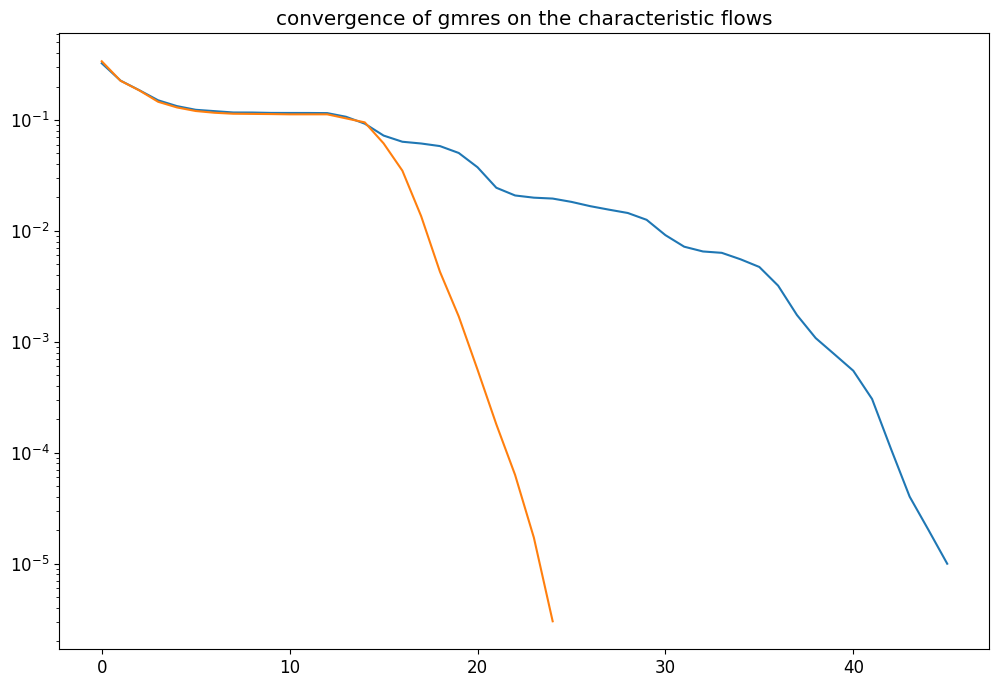

In [5]:
plt.semilogy(t_pipe.callbacks[0].residuals)
plt.semilogy(t_pipe.callbacks[1].residuals)
plt.title('convergence of gmres on the characteristic flows')
plt.show()

#### flows 

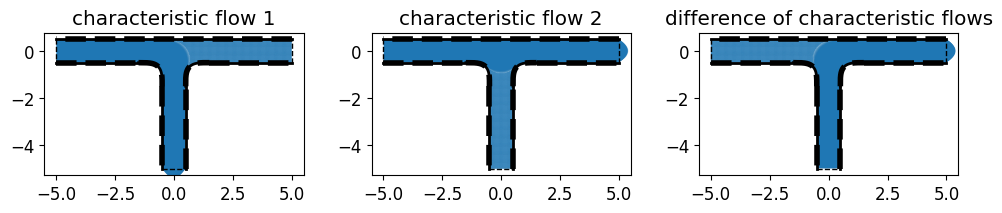

In [6]:
xs = t_pipe.xs
ys = t_pipe.ys

fig, axes = plt.subplots(1,3, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')
u0,v0,p0,o0 = t_pipe.fields_with_fluxes(np.array([1,0]),0,0)
t_pipe.exterior_boundary.plot_plyg_bdr(axes[0], color='k')
axes[0].quiver(xs, ys, u0, v0, scale=40, color='C0', width=0.003)
axes[0].set_title('characteristic flow 1')



axes[1].set_aspect('equal')
u1,v1,p1,o1 = t_pipe.fields_with_fluxes(np.array([0,1]),0,0)
t_pipe.exterior_boundary.plot_plyg_bdr(axes[1], color='k')
axes[1].quiver(xs, ys, u1, v1, scale=40, color='C0', width=0.003)
axes[1].set_title('characteristic flow 2')

axes[2].set_aspect('equal')
u2 = u1-u0
v2 = v1-v0
t_pipe.exterior_boundary.plot_plyg_bdr(axes[2], color='k')
axes[2].quiver(xs, ys, u2, v2, scale=40, color='C0', width=0.003, headwidth=10, headlength=10)
axes[2].set_title('difference of characteristic flows')

plt.show()

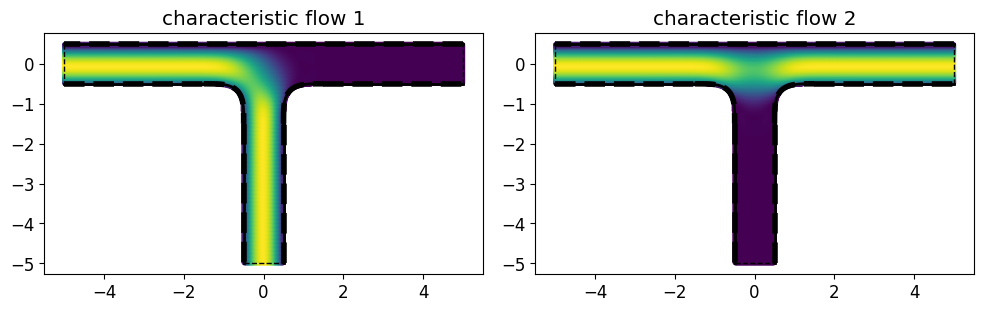

In [7]:
xs = t_pipe.xs
ys = t_pipe.ys

step = 1

fig, axes = plt.subplots(1,2, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')
u0,v0,p0,o0 = t_pipe.fields_with_fluxes(np.array([1,0]),0,0)
t_pipe.exterior_boundary.plot_plyg_bdr(axes[0], color='k')
axes[0].scatter(xs, ys, c=np.linalg.norm(np.array([u0,v0]),axis=0),s=10)
axes[0].set_title('characteristic flow 1')




axes[1].set_aspect('equal')
u1,v1,p1,o1 = t_pipe.fields_with_fluxes(np.array([0,1]),0,0)
t_pipe.exterior_boundary.plot_plyg_bdr(axes[1], color='k')
axes[1].scatter(xs, ys, c=np.linalg.norm(np.array([u1,v1]),axis=0),s=10)

axes[1].set_title('characteristic flow 2')

plt.show()

#### assembling the pipes

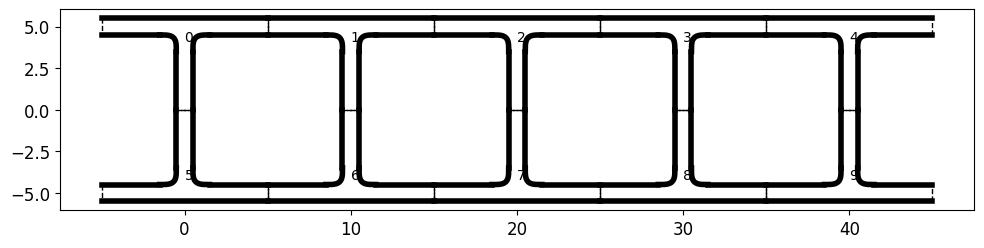

In [8]:
fig,ax = plt.subplots(figsize=(10,10),tight_layout=True)

pipes = [RealPipe(t_pipe,10*i,5,0) for i in range(5)] + \
    [RealPipe(t_pipe,10*i,-5,np.pi) for i in range(5)]


for i,pipe in enumerate(pipes):
    pipe.plot_plyg_bdr(ax)
    x = np.mean(pipe.xs)
    y = np.mean(pipe.ys)
    ax.text(x,y,f'{i}',fontsize=10)

ax.set_aspect('equal')
# ax.axis('off')

plt.show()

#### re-development of the pipe-system solver 

fundamental variables: 
- the coefficients of characteristic flows of all pipes

fundamental constraints:
- pressure is path-irrelavent
- flux is preserved at each connection

boundary conditions (imposed by users):
- either pressures at each boundary 
- or flux at each boundary


nodes are the connection point or boundary let. 

In [9]:
flows = []
for ip,p in enumerate(pipes):
    for iflow in range(p.n_flows):
        flows.append((ip,iflow))
flows = list(enumerate(flows))
flows_idx2flow = dict(flows)
flow2flows_idx = {flow:idx for idx,flow in flows}

In [10]:
from itertools import product

In [11]:
_traverse = dict()

for ip,p in enumerate(pipes):
    for il,l in enumerate(p.lets):
        _traverse[(ip,il)] = (p,l)
        
_nodes = []


# internal nodes
for ((ip1,il1), (p1,l1)),((ip2,il2), (p2,l2)) in product(_traverse.items(),repeat=2):
    if ip1>=ip2: 
        continue
    if l1.almost_match(l2):
        # create an internal node
        _nodes.append({
            'node_type': 'internal',
            'let0': (ip1,il1),
            'let1': (ip2,il2),
            'pos': (l1.x,l1.y),
        })
        
# boundary nodes
for ((ip,il), (p,l)) in _traverse.items():
    pos = np.array([l.x,l.y])
    dist = np.min([np.linalg.norm(pos - n['pos'])  for n in _nodes])
    if dist < 1e-6:
        continue
    
    _nodes.append({
        'node_type': 'boundary',
        'let': (ip,il),
        'pos': (l.x,l.y),
    })

In [12]:
# creating the flux equations at each node
n_flows = len(flows)
flux_equations = []
for n in _nodes:
    if n['node_type'] != 'internal':
        continue
    
    let0 = n['let0']
    let1 = n['let1']
    
    equation = np.zeros(n_flows)
    p0,l0 = let0
    p1,l1 = let1
    
    for i, (ip,iflow) in flows:
        
        '''
        this flow is from the 0-th let to the i-flow-1 -th let in the pipe ip. 
        '''
        if ip == p0 and l0 == iflow + 1:
            equation[i] = -1 # flowing into the node
        if ip == p1 and l1 == iflow + 1:
            equation[i] = -1 # flowing into the node
        if ip == p0 and l0 == 0:
            equation[i] = 1 # this flow flows out of the node
        if ip == p1 and l1 == 0:
            equation[i] = 1 # this flow flows out of the node
        
    
    flux_equations.append(equation)
flux_equations=np.array(flux_equations)


#### rotation testing 

Text(0.5, 1.0, 'difference of characteristic flows')

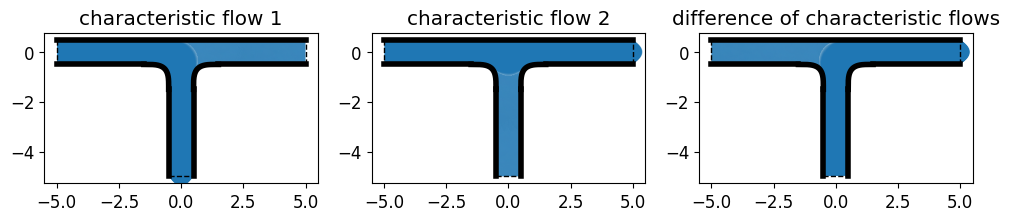

In [13]:
t_pipe_inverted = RealPipe(t_pipe,0,0,0)
xs = t_pipe_inverted.xs
ys = t_pipe_inverted.ys


fig, axes = plt.subplots(1,3, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')
u0,v0,p0,o0 = t_pipe_inverted.fields_with_fluxes(np.array([1,0]),0,0)
t_pipe_inverted.plot_plyg_bdr(axes[0], color='k')
axes[0].quiver(xs, ys, u0, v0, scale=40, color='C0', width=0.003)
axes[0].set_title('characteristic flow 1')

axes[1].set_aspect('equal')
u1,v1,p1,o1 = t_pipe_inverted.fields_with_fluxes(np.array([0,1]),0,0)
t_pipe_inverted.plot_plyg_bdr(axes[1], color='k')
axes[1].quiver(xs, ys, u1, v1, scale=40, color='C0', width=0.003)
axes[1].set_title('characteristic flow 2')

axes[2].set_aspect('equal')
u2 = u1-u0
v2 = v1-v0
t_pipe_inverted.plot_plyg_bdr(axes[2], color='k')
axes[2].quiver(xs, ys, u2, v2, scale=40, color='C0', width=0.003, headwidth=10, headlength=10)
axes[2].set_title('difference of characteristic flows')

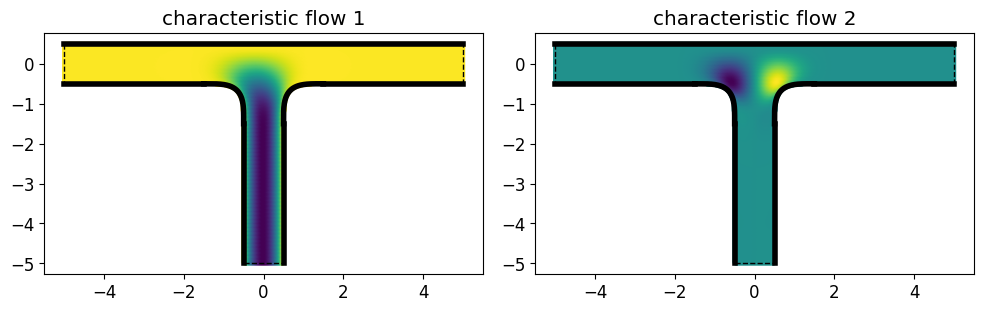

In [14]:
xs = t_pipe_inverted.xs
ys = t_pipe_inverted.ys

step = 1

fig, axes = plt.subplots(1,2, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')
u0,v0,p0,o0 = t_pipe_inverted.fields_with_fluxes(np.array([1,0]),0,0)
t_pipe_inverted.plot_plyg_bdr(axes[0], color='k')

cc = v0
axes[0].scatter(xs, ys, c=cc,s=10)
axes[0].set_title('characteristic flow 1')


axes[1].set_aspect('equal')
u1,v1,p1,o1 = t_pipe_inverted.fields_with_fluxes(np.array([0,1]),0,0)
t_pipe_inverted.plot_plyg_bdr(axes[1], color='k')
cc = v1
axes[1].scatter(xs, ys, c=cc,s=10)

axes[1].set_title('characteristic flow 2')

plt.show()

#### pressure drops 

Given an edge, find the pipe, and find the two lets, and two lets l0 and l1 in the pipe, what does each flow in the pipe affect the pressure drop between l0 and l1 ?

In [15]:
# create the graphs with all the edges
edges = []

def fn_lets(node):
    if node['node_type'] == 'internal':
        return [node['let0'],node['let1']]
    else:
        return [node['let']]
    
for ip,p in enumerate(pipes):
    for iflow in range(p.n_flows):
        
        start_let = (ip,0)    
        start_node_idx = [inode for inode,n in enumerate(_nodes) if start_let in fn_lets(n)][0]
        end_let = (ip,iflow+1)
        end_node_idx = [inode for inode,n in enumerate(_nodes) if end_let in fn_lets(n)][0]
        
        edges.append((start_node_idx,end_node_idx))


In [16]:
def fn_n2l(n):
    if n['node_type'] == 'internal':
        return [n['let0'],n['let1']]
    else:
        return [n['let']]

edges2pressure_drop = {}

for e in edges:
    n0 = _nodes[e[0]]
    n1 = _nodes[e[1]]
    
    l0 = fn_n2l(n0)
    l1 = fn_n2l(n1)
    
    cap = [(ll,lll) for ll, lll in product(l0,l1) if ll[0] == lll[0]]
    assert len(cap) == 1
    
    cap = cap[0]
    
    p = cap[0][0]
    l0 = cap[0][1]
    l1 = cap[1][1]
    
    pd = pipes[p].pressure_drops
    
    if l0 == 0:
        pd = pd[:,l1-1]
    elif l1 == 0:
        pd = -pd[:,l0-1]
    else: 
        pd = pd[:,l1-1] - pd[:,l0-1]
    
    pdf = np.zeros(len(flows))
    
    idx = [i for i,(j,k) in flows if j==p]
    
    pdf[idx] = pd
    
    edges2pressure_drop[e] = pdf
    
    
    reverse_e = (e[1],e[0])
    edges2pressure_drop[reverse_e] = -pdf

In [17]:
import networkx as nx

g = nx.Graph()
g.add_nodes_from(range(len(_nodes)))
g.add_edges_from(edges)

cycles = nx.cycle_basis(g)


# pressure drop equations

pressure_drop_equations = []
for c in cycles:
    eq = np.zeros(len(flows))
    for e in zip(c,c[1:]+[c[0]]):
        eq += edges2pressure_drop[e]
    
    pressure_drop_equations.append(eq)

pressure_drop_equations = np.vstack(pressure_drop_equations)

In [18]:
laws = np.vstack([pressure_drop_equations,flux_equations])

#### create the equation for the flux at all the boundary lets

In [19]:
# perscribe the flux at boundary let 

f_equations = []
boundary_lets = [n for n in _nodes if n['node_type'] == 'boundary']

for n in boundary_lets[:-1]:
    p,l = n['let']
    
    equation = np.zeros(n_flows)
    
    if l == 0:
        
        flow_idx = [i for i,(j,k) in flows if j == p]
        equation[flow_idx] = 1
        # flow in
        
    else:
        flow_idx = [i for i,(j,k) in flows if (j,k) == (p,l-1)]
        assert len(flow_idx) == 1
        flow_idx = flow_idx[0]
        equation[flow_idx] = -1
        # flow out
        
    f_equations.append(equation)
    
def flux_to_flow(flux):
    assert len(flux) == len(boundary_lets), f'flux should have {len(boundary_lets)} elements'
    assert np.isclose(np.sum(flux),0), f'net flux should be zero'
    
    A = np.vstack([f_equations,laws])
    b = np.concatenate([flux[:-1],np.zeros(laws.shape[0])])
    
    x = np.linalg.solve(A,b)
    
    return x
    

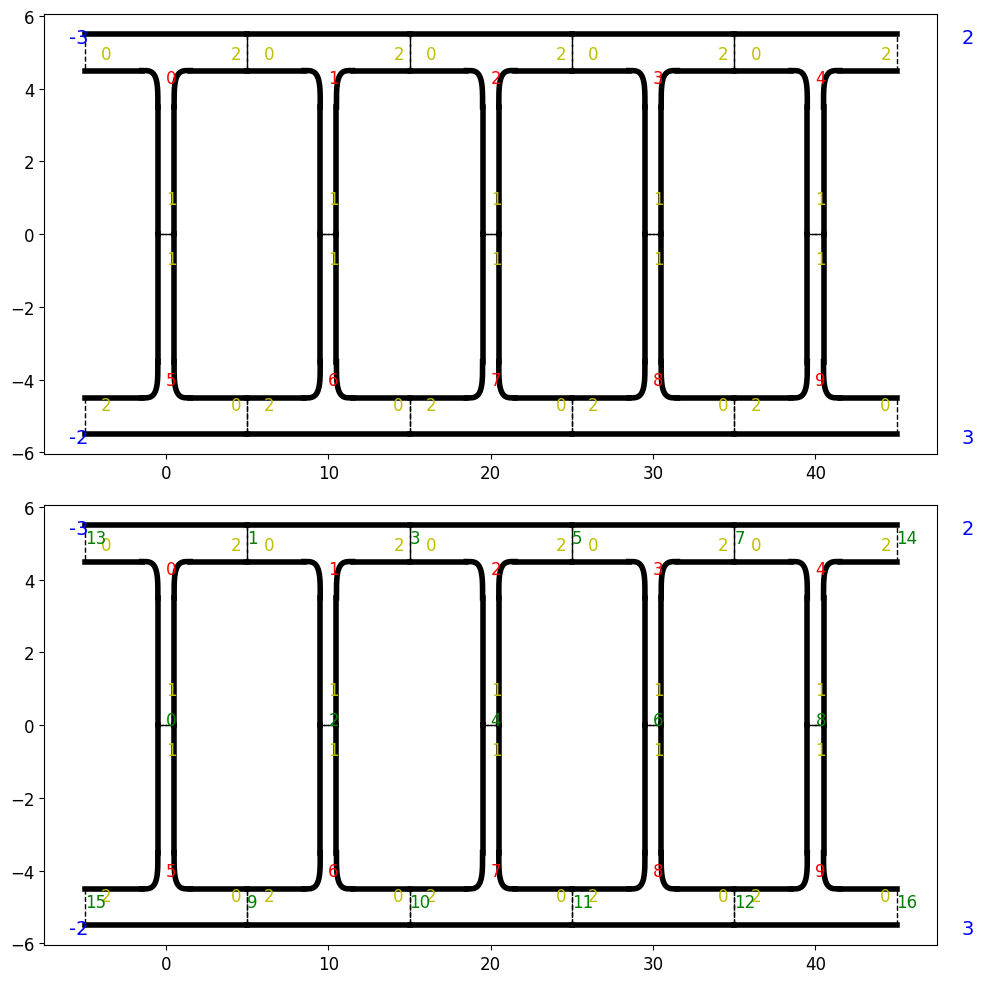

In [20]:
fig,axes = plt.subplots(2,1,figsize=(10,10), tight_layout=True)

bflux = [-3,2,-2,3]


for blet,bf in zip(boundary_lets,bflux):
    pos = np.array(blet['pos'])
    center = np.array([5,2.5])
    
    t = 0.1
    
    pos = (1+t)*pos - t*center
    
    axes[0].text(pos[0],pos[1],f'{bf}',fontsize=14,color='b')
    axes[1].text(pos[0],pos[1],f'{bf}',fontsize=14,color='b')
    
for ip,p in enumerate(pipes):
    c = np.array([np.mean(p.xs),np.mean(p.ys)])
    
    p.plot_plyg_bdr(axes[0], color='k')
    p.plot_plyg_bdr(axes[1], color='k')
    
    axes[0].text(c[0],c[1],f'{ip}',fontsize=12,color='r')
    axes[1].text(c[0],c[1],f'{ip}',fontsize=12,color='r')
    
    for il,l in enumerate(p.lets):
        pos = np.array([l.x,l.y])*0.8 + c*0.2
        axes[0].text(pos[0],pos[1],f'{il}',fontsize=12,color='y')
        axes[1].text(pos[0],pos[1],f'{il}',fontsize=12,color='y')

for inode,n in enumerate(_nodes):
    plt.text(n['pos'][0],n['pos'][1],f'{inode}',fontsize=12,color='g')
    

    

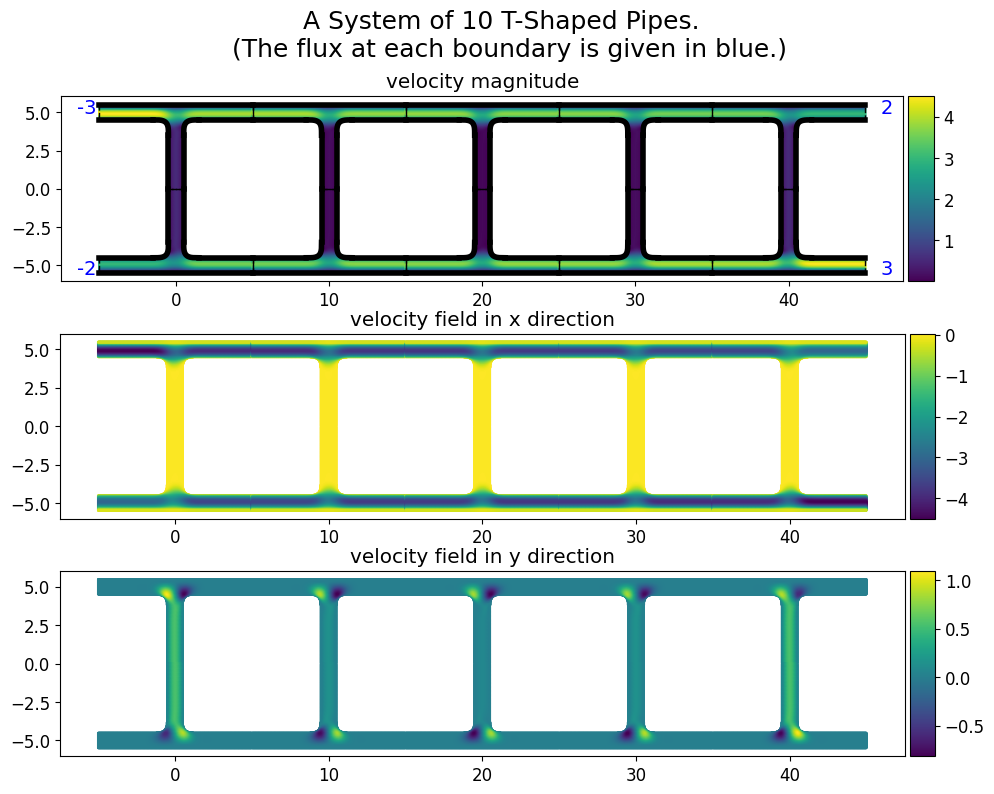

In [39]:
flow_coef = flux_to_flow(bflux)


us = []
vs = []
xs = []
ys = []

for pidx,p in enumerate(pipes):    
    flow_idx = [i for i,(j,k) in flows if j==pidx] 
    coef = flow_coef[flow_idx]
    u,v,_,_ =  p.fields_with_fluxes(coef,0,0)
    
    # if pidx == 1:
    us.append(u)
    vs.append(v)
    xs.append(p.xs)
    ys.append(p.ys)

us = np.concatenate(us)
vs = np.concatenate(vs)
xs = np.concatenate(xs)
ys = np.concatenate(ys)

fig,axes = plt.subplots(3,1,figsize=(10,8),tight_layout=True)


for blet,bf in zip(boundary_lets,bflux):
    pos = np.array(blet['pos'])
    center = np.array([5,2.5])
    
    t = 0.05
    
    pos = (1+t)*pos - t*center + np.array([-1,-0.2])
    
    axes[0].text(pos[0],pos[1],f'{bf}',fontsize=14,color='b')

for ax in axes:
    ax.set_aspect('equal')    
    
    
axes[0].scatter(xs,ys,c=np.sqrt(us**2+vs**2),s=1)
axes[0].set_title('velocity magnitude')

for ip,p in enumerate(pipes):
    c = np.array([np.mean(p.xs),np.mean(p.ys)])

    p.plot_plyg_bdr(axes[0], color='k')

from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(axes[0])
cax = divider.append_axes("right", size="3%", pad=0.05)
plt.colorbar(axes[0].collections[0], cax=cax)



axes[1].set_title('velocity field in x direction')
axes[1].scatter(xs,ys,c=us,s=1)
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(axes[1])
cax = divider.append_axes("right", size="3%", pad=0.05)
plt.colorbar(axes[1].collections[0], cax=cax)



axes[2].scatter(xs,ys,c=vs,s=1)
axes[2].set_title('velocity field in y direction')
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(axes[2])
cax = divider.append_axes("right", size="3%", pad=0.05)
plt.colorbar(axes[2].collections[0], cax=cax)


fig.suptitle('A System of 10 T-Shaped Pipes. \n (The flux at each boundary is given in blue.)', fontsize=18)


plt.show()